<h1 align="center">Assignment 4</h1>

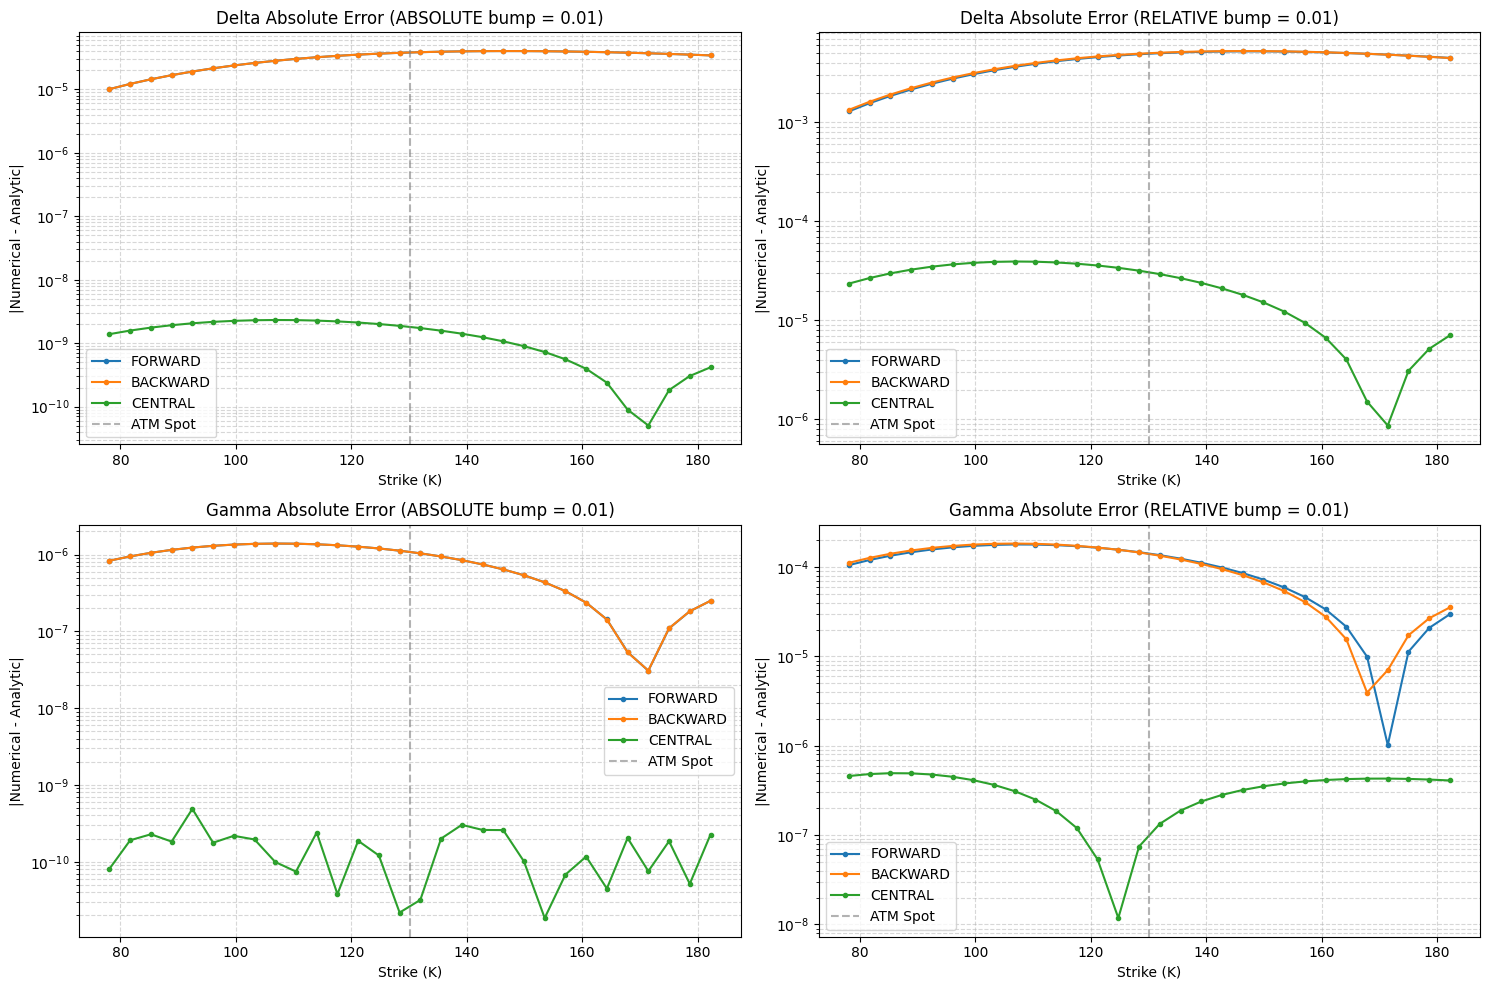

In [8]:
%matplotlib inline
import importlib
import enums
import market_data
import model
import pricer

importlib.reload(enums)
importlib.reload(market_data)
importlib.reload(model)
importlib.reload(pricer)

import numpy as np
import matplotlib.pyplot as plt
from market_data import MarketData
from model import MarketModel
from pricer import EuropeanAnalyticPricer, Pricer, Params
from contract import EuropeanContract
from enums import Stock, PutCallFwd, LongShort, GreekMethod, DiffMethod, BumpType

und = Stock.BLUECHIP_BANK
model = MarketModel(und)
spot = model.spot

strikes = np.linspace(spot * 0.6, spot * 1.4, 30)
expiry = 1.0
contracts = [EuropeanContract(und, PutCallFwd.CALL, LongShort.LONG, k, expiry) for k in strikes]

Pricer.bump_size = 0.01

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for col, b_type in enumerate([BumpType.ABSOLUTE, BumpType.RELATIVE]):
    Pricer.bump_type = b_type
    
    for d_method in [DiffMethod.FORWARD, DiffMethod.BACKWARD, DiffMethod.CENTRAL]:
        Pricer.diff_method = d_method
        
        delta_err = []
        gamma_err = []
        
        for c in contracts:
            pricer = EuropeanAnalyticPricer(c, model, Params(bump_size=0.01))
            
            
            d_ana = pricer.calc_delta(GreekMethod.ANALYTIC)
            d_num = pricer.calc_delta(GreekMethod.BUMP)
            delta_err.append(abs(d_num - d_ana))
            
        
            g_ana = pricer.calc_gamma(GreekMethod.ANALYTIC)
            g_num = pricer.calc_gamma(GreekMethod.BUMP)
            gamma_err.append(abs(g_num - g_ana))
            
        axes[0, col].plot(strikes, delta_err, label=d_method.value, marker='o', markersize=3)
        axes[1, col].plot(strikes, gamma_err, label=d_method.value, marker='o', markersize=3)

    axes[0, col].axvline(spot, color='gray', linestyle='--', alpha=0.6, label='ATM Spot')
    axes[0, col].set_title(f'Delta Absolute Error ({b_type.value} bump = 0.01)')
    axes[0, col].set_xlabel('Strike (K)')
    axes[0, col].set_ylabel('|Numerical - Analytic|')
    axes[0, col].set_yscale('log')
    axes[0, col].legend()
    axes[0, col].grid(True, which='both', linestyle='--', alpha=0.5)

    axes[1, col].axvline(spot, color='gray', linestyle='--', alpha=0.6, label='ATM Spot')
    axes[1, col].set_title(f'Gamma Absolute Error ({b_type.value} bump = 0.01)')
    axes[1, col].set_xlabel('Strike (K)')
    axes[1, col].set_ylabel('|Numerical - Analytic|')
    axes[1, col].set_yscale('log')
    axes[1, col].legend()
    axes[1, col].grid(True, which='both', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

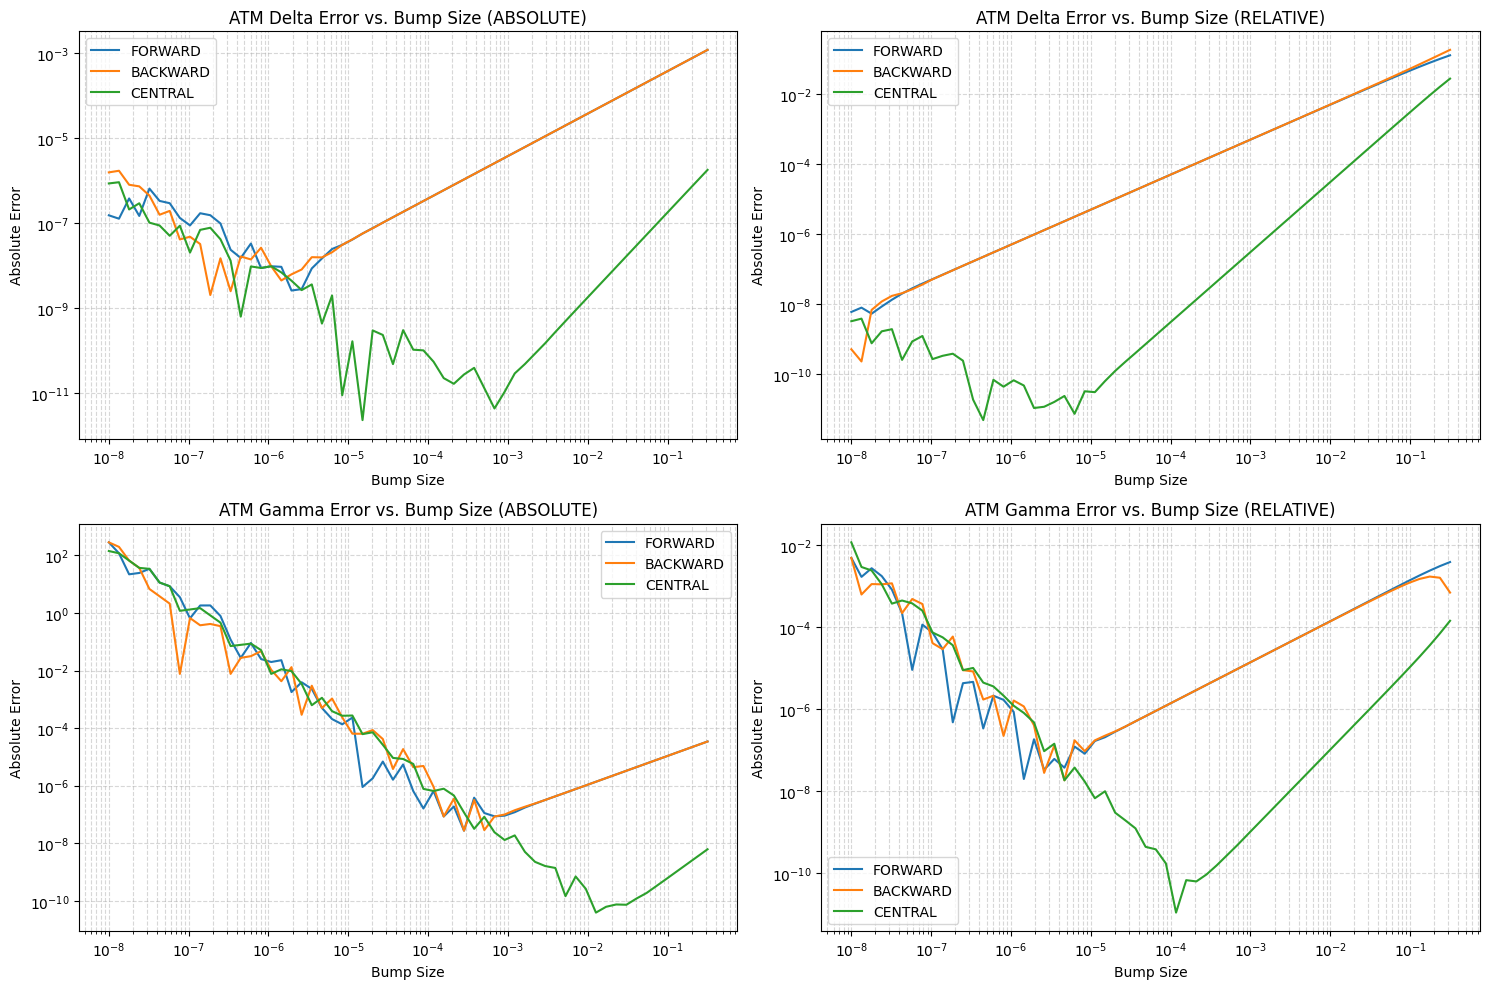

In [9]:
atm_contract = EuropeanContract(und, PutCallFwd.CALL, LongShort.LONG, spot, expiry)
bump_grid = np.logspace(-8, -0.5, 60)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for col, b_type in enumerate([BumpType.ABSOLUTE, BumpType.RELATIVE]):
    Pricer.bump_type = b_type
    
    for d_method in [DiffMethod.FORWARD, DiffMethod.BACKWARD, DiffMethod.CENTRAL]:
        Pricer.diff_method = d_method
        
        d_errors = []
        g_errors = []
        
        for b in bump_grid:
            pricer = EuropeanAnalyticPricer(atm_contract, model, Params(bump_size=b))
            
            d_ana = pricer.calc_delta(GreekMethod.ANALYTIC)
            d_num = pricer.calc_delta(GreekMethod.BUMP)
            d_errors.append(abs(d_num - d_ana))
            
            g_ana = pricer.calc_gamma(GreekMethod.ANALYTIC)
            g_num = pricer.calc_gamma(GreekMethod.BUMP)
            g_errors.append(abs(g_num - g_ana))
            
        axes[0, col].loglog(bump_grid, d_errors, label=d_method.value)
        axes[1, col].loglog(bump_grid, g_errors, label=d_method.value)

    axes[0, col].set_title(f'ATM Delta Error vs. Bump Size ({b_type.value})')
    axes[0, col].set_xlabel('Bump Size')
    axes[0, col].set_ylabel('Absolute Error')
    axes[0, col].legend()
    axes[0, col].grid(True, which='both', linestyle='--', alpha=0.5)

    axes[1, col].set_title(f'ATM Gamma Error vs. Bump Size ({b_type.value})')
    axes[1, col].set_xlabel('Bump Size')
    axes[1, col].set_ylabel('Absolute Error')
    axes[1, col].legend()
    axes[1, col].grid(True, which='both', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Comparison of absolute and relative bumping:
In absolute bumping, the step size is simply h = bump_size. In relative bumping, the step size is scaled by the spot price, so h = spot * bump_size. Since our spot price is 130.17, a relative bump results in a step size that is about 130 times larger than an absolute bump of the same value. This is why the relative error curves are shifted to the left by roughly two orders of magnitude on the plots. In practice, relative bumping is usually preferred because it scales automatically with the price of the underlying asset, whereas a fixed absolute bump might be too large for cheap stocks or too small for expensive ones.

Suggested optimal bump sizes:
The optimal bump size is at the bottom of the V-shaped curves, where the combination of truncation error and floating-point round-off error is minimal. Since the central difference method is more accurate than the forward and backward methods, it reaches its minimum error at larger bump sizes.

Based on the plots, the optimal bump sizes are:
- Delta (central difference): around $10^{-4}$ to $10^{-3}$ for absolute, and $10^{-6}$ to $10^{-5}$ for relative bumping.
- Delta (forward/backward difference): around $10^{-6}$ for absolute, and $10^{-8}$ for relative bumping.
- Gamma (central difference): around $10^{-3}$ to $10^{-2}$ for absolute, and $10^{-5}$ to $10^{-4}$ for relative bumping.
- Gamma (forward/backward difference): around $10^{-4}$ to $10^{-3}$ for absolute, and $10^{-6}$ to $10^{-5}$ for relative bumping.

Overall, using the central difference method with a relative bump size of around $10^{-4}$ (1 basis point) is a good choice for calculating both Delta and Gamma.